In [1]:
class Vec2:
    def __init__(self, x, y):
        self.x = x
        self.y = y

    def add(self, v2):
        return Vec2(self.x + v2.x, self.y + v2.y)

    def scale(self, scalar):
        return Vec2(scalar * self.x, scalar * self.y)

    def __eq__(self, other):
        return self.x == other.x and self.y == other.y

    def __add__(self, v2):
        return self.add(v2)

    def __mul__(self, scalar):
        return self.scale(scalar)

    def __rmul__(self, scalar):
        return self.scale(scalar)

    def __repr__(self):
        return f"Vec2({self.x},{self.y})"


In [2]:
v = Vec2(3, 4)
w = v.add(Vec2(-2, 6))
print(w.x)

1


In [3]:
3.0 * Vec2(1, 0) + 4.0 * Vec2(0, 1)

Vec2(3.0,4.0)

In [4]:
class Vec3:
    def __init__(self, x, y, z):
        self.x = x
        self.y = y
        self.z = z

    def add(self, v3):
        return Vec3(self.x + v3.x, self.y + v3.y, self.z + v3.z)

    def scale(self, scalar):
        return Vec3(scalar * self.x, scalar * self.y, scalar * self.z)

    def __eq__(self, other):
        return self.x == other.x and self.y == other.y and self.z == other.z

    def __add__(self, v3):
        return self.add(v3)

    def __mul__(self, scalar):
        return self.scale(scalar)

    def __rmul__(self, scalar):
        return self.scale(scalar)

    def __repr__(self):
        return f"Vec3({self.x},{self.y},{self.z})"

In [5]:
2.0 * Vec3(1, 0, 0) + 3.0 * Vec3(0, 1, 0) + 4.0 * Vec3(0, 0, 1)

Vec3(2.0,3.0,4.0)

In [6]:
def average(v1, v2):
    return 0.5 * v1 + 0.5 * v2

In [7]:
from abc import ABCMeta, abstractmethod


class Vector(metaclass=ABCMeta):
    @abstractmethod
    def add(self, other):
        pass

    @abstractmethod
    def scale(self, scalar):
        pass

    def __add__(self, other):
        return self.add(other)

    def __mul__(self, scalar):
        return self.scale(scalar)

    def __rmul__(self, scalar):
        return self.scale(scalar)

    def subtract(self, other):
        return self.add(-1 * other)

    def __sub__(self, other):
        return self.subtract(other)

In [8]:
class Vec2(Vector):
    def __init__(self, x, y):
        self.x = x
        self.y = y

    def add(self, other):
        return Vec2(self.x + other.x, self.y + other.y)

    def scale(self, scalar):
        return Vec2(scalar * self.x, scalar * self.y)

    def __eq__(self, other):
        return self.x == other.x and self.y == other.y

    def __repr__(self):
        return f"Vec2({self.x},{self.y})"

In [9]:
from random import uniform
from math import isclose


def random_scalar():
    return uniform(-10, 10)


def random_vec2():
    return Vec2(random_scalar(), random_scalar())


def approx_equal_vec2(v, w):
    return isclose(v.x, w.x) and isclose(v.y, w.y)


a = random_scalar()
u, v = random_vec2(), random_vec2()
assert approx_equal_vec2(a * (u + v), a * u + a * v)


def test(eq, a, b, u, v, w):
    assert eq(u + v, v + u)
    assert eq(u + (v + w), (u + v) + w)
    assert eq(a * (b * v), (a * b) * v)
    assert eq(1 * v, v)
    assert eq((a + b) * v, a * v + b * v)
    assert eq(a * v + a * w, a * (v + w))


for i in range(0, 100):
    a, b = random_scalar(), random_scalar()
    u, v, w = random_vec2(), random_vec2(), random_vec2()
    test(approx_equal_vec2, a, b, u, v, w)


In [10]:
class Vec1(Vector):
    def __init__(self, x):
        self.x = x

    def add(self, other):
        return Vec1(self.x + other.x)

    def scale(self, scalar):
        return Vec1(scalar * self.x)

    @classmethod
    def zero(cls):
        return Vec1(0)

    def __eq__(self, other):
        return self.x == other.x

    def __repr__(self):
        return "Vec1({})".format(self.x)


In [11]:
Vec1.zero()

Vec1(0)

In [12]:
class Vec0(Vector):
    def __init__(self):
        pass

    def add(self, other):
        return Vec0()

    def scale(self, scalar):
        return Vec0()

    @classmethod
    def zero(cls):
        return Vec0()

    def __eq__(self, other):
        return self.__class__ == other.__class__ == Vec0

    def __repr__(self):
        return "Vec0()"


In [13]:
-3.14 * Vec0()

Vec0()

In [14]:
from datetime import datetime


class CarForSale(Vector):
    retrieved_date = datetime(2018, 11, 30, 12)  # 1

    def __init__(
        self,
        model_year,
        mileage,
        price,
        posted_datetime,
        model="(virtual)",
        source="(virtual)",  # 2
        location="(virtual)",
        description="(virtual)",
    ):
        self.model_year = model_year
        self.mileage = mileage
        self.price = price
        self.posted_datetime = posted_datetime
        self.model = model
        self.source = source
        self.location = location
        self.description = description

    def add(self, other):
        def add_dates(d1, d2):  # 3
            age1 = CarForSale.retrieved_date - d1
            age2 = CarForSale.retrieved_date - d2
            sum_age = age1 + age2
            return CarForSale.retrieved_date - sum_age

        return CarForSale(  # 4
            self.model_year + other.model_year,
            self.mileage + other.mileage,
            self.price + other.price,
            add_dates(self.posted_datetime, other.posted_datetime),
        )

    def scale(self, scalar):
        def scale_date(d):  # 5
            age = CarForSale.retrieved_date - d
            return CarForSale.retrieved_date - (scalar * age)

        return CarForSale(
            scalar * self.model_year,
            scalar * self.mileage,
            scalar * self.price,
            scale_date(self.posted_datetime),
        )

    @classmethod
    def zero(cls):
        return CarForSale(0, 0, 0, CarForSale.retrieved_date)


In [15]:
from json import loads, dumps
from pathlib import Path
from datetime import datetime

contents = Path("cargraph.json").read_text()
cg = loads(contents)
cleaned = []


def parse_date(s):
    input_format = "%m/%d - %H:%M"
    return datetime.strptime(s, input_format).replace(year=2018)

    return dt


for car in cg[1:]:
    try:
        row = CarForSale(
            int(car[1]),
            float(car[3]),
            float(car[4]),
            parse_date(car[6]),
            car[2],
            car[5],
            car[7],
            car[8],
        )
        cleaned.append(row)
    except:
        pass

cars = cleaned


/var/folders/gz/mpz2ln4x1g5fp9yy0vvz7fw80000gn/T/ipykernel_40006/3219851358.py:12: DeprecationWarning: Parsing dates involving a day of month without a year specified is ambiguous
and fails to parse leap day. The default behavior will change in Python 3.15
to either always raise an exception or to use a different default year (TBD).
To avoid trouble, add a specific year to the input & format.
See https://github.com/python/cpython/issues/70647.
  return datetime.strptime(s, input_format).replace(year=2018)


In [16]:
cars[1].__dict__

{'model_year': 2007,
 'mileage': 192000.0,
 'price': 2600.0,
 'posted_datetime': datetime.datetime(2018, 11, 30, 9, 15),
 'model': 'Prius',
 'source': 'craigslist',
 'location': 'New York City, NY',
 'description': 'Toyota prius 2007'}

In [17]:
(cars[0] + cars[1]).__dict__

{'model_year': 4012,
 'mileage': 306000.0,
 'price': 6100.0,
 'posted_datetime': datetime.datetime(2018, 11, 30, 3, 59),
 'model': '(virtual)',
 'source': '(virtual)',
 'location': '(virtual)',
 'description': '(virtual)'}

In [18]:
average_prius = sum(cars, CarForSale.zero()) * (1.0 / len(cars))
average_prius.__dict__

{'model_year': 2012.5365853658536,
 'mileage': 87731.63414634147,
 'price': 12574.731707317074,
 'posted_datetime': datetime.datetime(2018, 11, 30, 9, 0, 49, 756098),
 'model': '(virtual)',
 'source': '(virtual)',
 'location': '(virtual)',
 'description': '(virtual)'}

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from math import sin


def plot(fs, xmin, xmax):
    xs = np.linspace(xmin, xmax, 100)
    _fig, ax = plt.subplots()
    ax.axhline(y=0, color='k')
    ax.axvline(x=0, color='k')
    for f in fs:
        ys = [f(x) for x in xs]
        plt.plot(xs, ys)

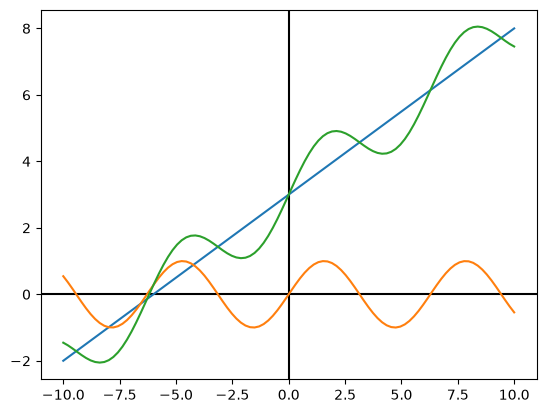

In [25]:
def f(x):
    return 0.5 * x + 3
def g(x):
    return sin(x)
def add_functions(f, g):
    return lambda x: f(x) + g(x)

plot([f, g, add_functions(f, g)], -10, 10)

In [ ]:
class Matrix5_by_3(Vector):
    rows = 5
    columns = 3

    def __init__(self, matrix):
        self.matrix = matrix

    def add(self, other):
        return Matrix5_by_3(
            tuple(
                tuple(a + b for a, b in zip(row1, row2))
                for (row1, row2) in zip(self.matrix, other.matrix)
            )
        )

    def scale(self, scalar):
        return Matrix5_by_3(
            tuple(tuple(scalar * x for x in row) for row in self.matrix)
        )

    @classmethod
    def zero(cls):
        return Matrix5_by_3(
            tuple(tuple(0 for _ in range(cls.columns)) for _ in range(cls.rows))
        )